In [41]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
df.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [7]:
df['furnishingstatus'].nunique()

3

In [8]:
columns_to_transform=['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']
df[columns_to_transform]=df[columns_to_transform].replace({'yes': 1, 'no': 0})

df['furnishingstatus']=df['furnishingstatus'].replace({'unfurnished': 0,'semi-furnished': 1,'furnished': 2})

In [31]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [10]:
scaler=StandardScaler()
sc=['price', 'area']
df[sc]=scaler.fit_transform(df[sc])

In [11]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,4.566365,1.046726,4,2,3,1,0,0,0,1,2,1,2
1,4.004484,1.757010,4,4,4,1,0,0,0,1,3,0,2
2,4.004484,2.218232,3,2,2,1,0,1,0,0,2,1,1
3,3.985755,1.083624,4,2,2,1,0,1,0,1,3,1,2
4,3.554979,1.046726,4,1,2,1,1,1,0,1,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,-1.576868,-0.991879,2,1,1,1,0,1,0,0,2,0,0
541,-1.605149,-1.268613,3,1,1,0,0,0,0,0,0,0,1
542,-1.614327,-0.705921,2,1,1,1,0,0,0,0,0,0,0
543,-1.614327,-1.033389,3,1,1,0,0,0,0,0,0,0,2


In [12]:
df.dtypes

price               float64
area                float64
bedrooms              int64
bathrooms             int64
stories               int64
mainroad             object
guestroom            object
basement             object
hotwaterheating      object
airconditioning      object
parking               int64
prefarea             object
furnishingstatus     object
dtype: object

In [13]:
corr_matrix=df.corr()

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

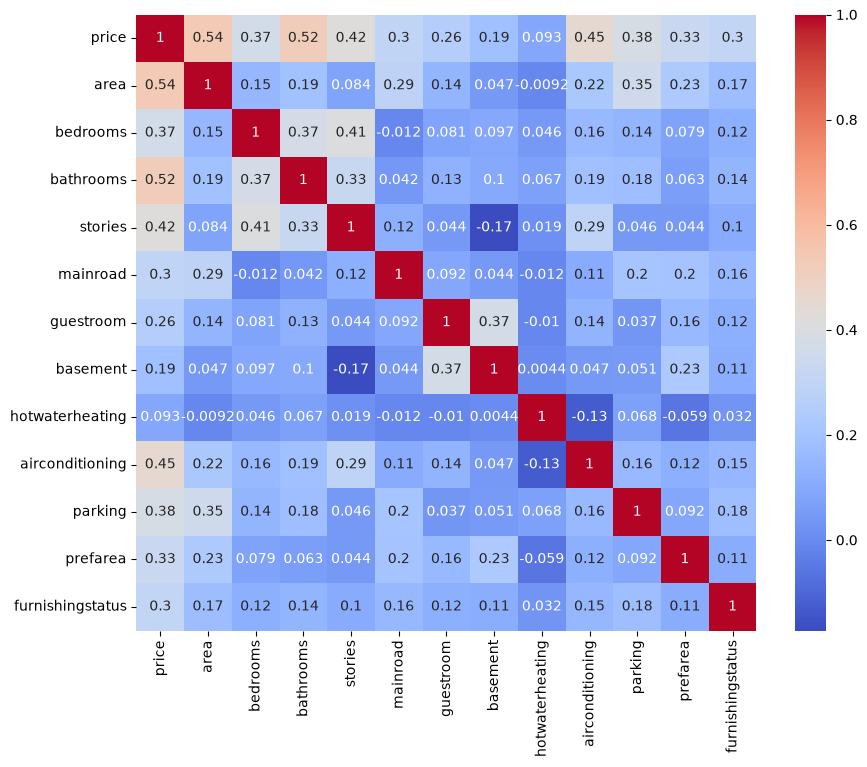

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm")
plt.show()

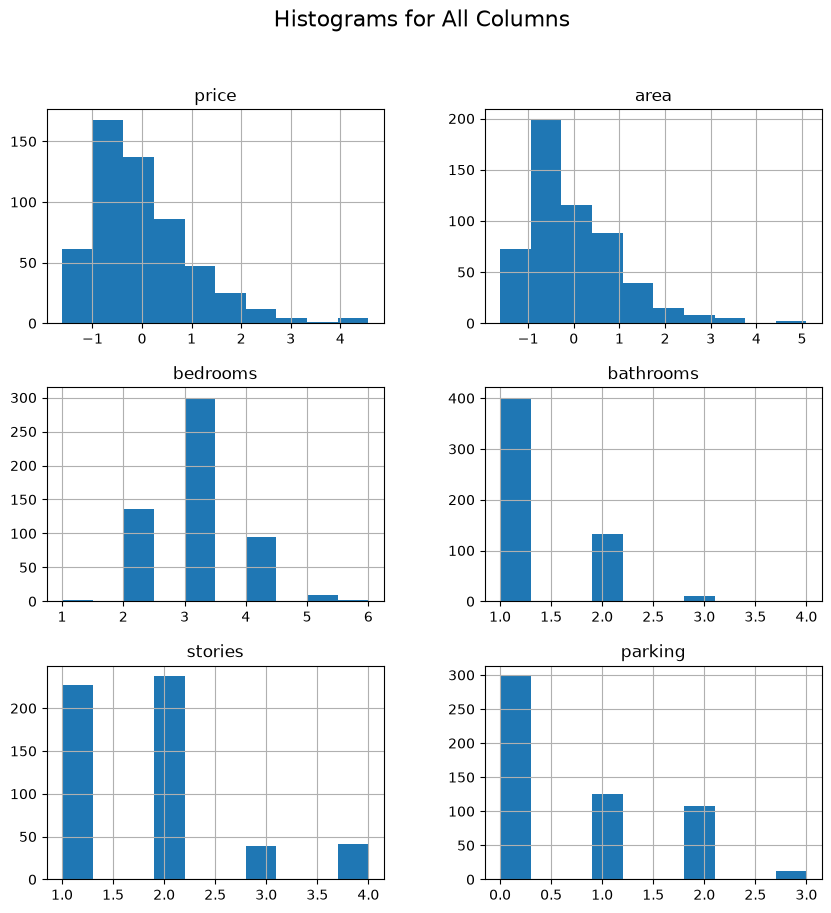

In [16]:
df.hist(figsize=(10, 10), bins=10)
plt.suptitle("Histograms for All Columns",fontsize=16)
plt.show()

In [26]:
X=df.drop('price', axis=1)
y=df['price']

In [27]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["int64","float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

In [29]:
from sklearn.compose import ColumnTransformer

In [32]:
# Preprocessing
preprocessor = ColumnTransformer([("num", StandardScaler(), numerical_features),("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)])

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
# Split data before fitting preprocessing
X_train,X_test,y_train,y_test =train_test_split( X, y, test_size=0.2, random_state=42)

### Multiple Machine Learning models

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [36]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [42]:
# Train and evaluate
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
results_df.sort_values("R2 Score", ascending=False)

,Model,R2 Score,MAE,RMSE
3,Gradient Boosting,0.666116,0.517343,0.695176
0,Linear Regression,0.652924,0.519094,0.708777
2,Random Forest,0.619054,0.540145,0.742556
1,Decision Tree,0.440640,0.653603,0.899794


### Model Performance Visualization

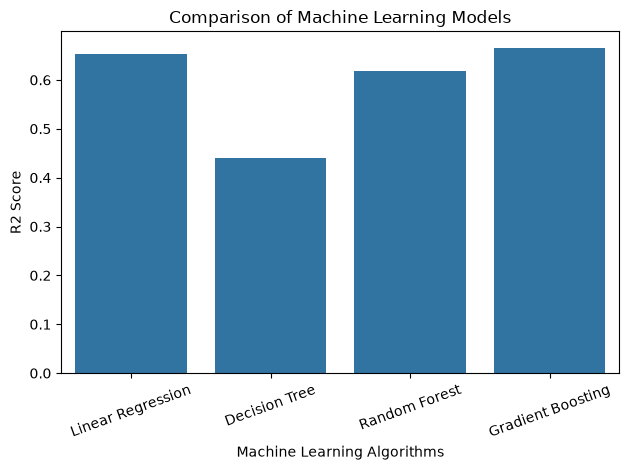

In [44]:
sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Feature Importance Analysis

In [45]:
from sklearn.inspection import permutation_importance

In [46]:
# Select the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]


In [47]:
# Calculate feature importance
importance = permutation_importance(best_model,X_test,y_test,n_repeats=10, random_state=42, scoring="r2")
importance_df = pd.DataFrame({"Feature": X.columns,"Importance": importance.importances_mean}).sort_values("Importance", ascending=False)

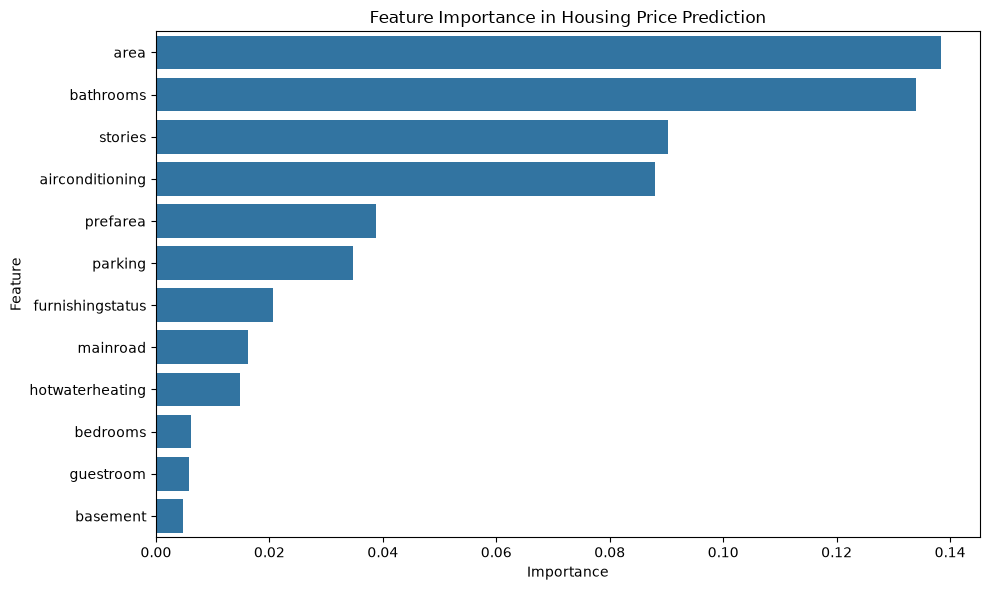

In [48]:
# Visualize
plt.figure(figsize=(10, 6))

sns.barplot(data=importance_df,x="Importance",y="Feature")

plt.title("Feature Importance in Housing Price Prediction")
plt.tight_layout()
plt.show()


In [50]:
# Example house details
new_house = pd.DataFrame([{
    "area": 5000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "no",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 2,
    "prefarea": "yes",
    "furnishingstatus": "furnished"
}])

In [51]:
# Predict using the best model
predicted_price = best_model.predict(new_house)

print("Selected Model:", best_model_name)
print("Predicted House Price:", round(predicted_price[0], 2))

Selected Model: Linear Regression
Predicted House Price: 1369.83
